## Welcome back to exercise class 9: Today is about FEVD and HDecomp.

In [62]:
# Reset everything with %reset -f
%reset -f

# Load data.txt as dataframe
from s_master_2 import *

from scipy import optimize
from scipy.optimize import fsolve
from statsmodels.tsa.tsatools import vec, vech
from scipy.optimize import least_squares
import matplotlib.pyplot as plt

from Own_functions import johcontest_py

data = pd.read_csv('data-1.txt', sep=',', header=0)
print(data)


            y         c        in
0    0.800000  0.600000  0.400000
1    0.801386  0.612503  0.368379
2    0.800871  0.609492  0.401194
3    0.815026  0.604507  0.471828
4    0.816375  0.610173  0.495708
..        ...       ...       ...
163  1.476822  1.352386  1.124347
164  1.489725  1.360701  1.129651
165  1.494235  1.365882  1.152387
166  1.502511  1.373010  1.160044
167  1.501020  1.377705  1.159704

[168 rows x 3 columns]


#### Set up the model

As in exercise 8, we set up an identical model to KSPW:

In [63]:
# Data to numpy
y = np.array(data)
exog = 0
p = 9
model = 3

(lr1, cval5, cval10, pval, l, beta, alpha, c0, c1, d0, d1) = jcitestexog(y,p-1,exog,model)


# Impose the cointegration restriction
beta = np.array([[-1, 1, 0], [-1, 0, 1]]).T

r = 2 # rank determined by jcitest

t, K = y.shape

# These are the unresticted estimates of beta and alpha
betaorg = beta[:, 0:r]
alphaorg = alpha[:, 0:r]


# Need to make sure that c0, c1, d0 and d1 are all arrays
if len(c0)>1:
  c0 = np.reshape(np.array(c0), (K-1,1))
else:
  c0 = c0.reshape(-1,1)
  
if len(c1)>1:
  c1 = np.reshape(np.array(c1), (K,1))
else:
  c1 = c1.reshape(-1,1)

if len(d0)>1:
  d0 = np.reshape(np.array(d0), (K-1,1))
else:
  d0 = d0.reshape(-1,1)

if len(d1)>1:
  d1 = np.reshape(np.array(d1), (K,1))
else:
  d1 = d1.reshape(-1,1)

# Then we construct cointegration vector(s) depending on model and rank r
alpha = alpha[:,0:r]
beta = beta[:,0:r]
if model==1:
    beta = beta
elif model==2:
    beta = np.hstack((beta.T,c0[0:r])).T
elif model==3:
    beta = np.hstack((beta.T,c0[0:r])).T
elif model==4:
    beta = np.hstack((np.hstack((beta.T,c0[0:r])),d0[0:r])).T
elif model==5:
    beta = np.hstack((np.hstack((beta.T,c0[0:r])),d0[0:r])).T

    
[Beta, Betavec, SEBeta, tratioBeta, res, so, so_ml] = LSKnownBeta(y,p,beta.T,model)

Beta = Beta.T

GAMMA = Beta[:,0:K*(p-1)]       # first diff lags
alpha = Beta[:,K*(p-1):len(Beta.T)-1]   # speed of adjustment
mu = Beta[:, -1]

beta_perp = null(betaorg.T)
beta_perp = beta_perp[1]
alpha_perp = null(alpha.T)
alpha_perp = alpha_perp[1]

GammaSum = GAMMA[0:K,0:K]

if p > 2:
  for i in range(1,p - 1):
      GammaSum = GammaSum+GAMMA[0:K,i*K:i*K+K]

Xi= beta_perp @ np.linalg.inv(alpha_perp.T @ (np.identity(K)-GammaSum) @ beta_perp) @ alpha_perp.T


SIGMA = so

# Define the restrictions function
def restrictions(B0inv_flat):
    # Reshape B0inv from a flat array to a K x K matrix
    K = int(np.sqrt(len(B0inv_flat)))
    B0inv = B0inv_flat.reshape((K, K))
    
    # Compute THETA1
    Upsilon = Xi @ B0inv
    
    # Compute F = vec(B0inv * B0inv' - SIGMA)
    F = vech(B0inv @ B0inv.T - SIGMA[:K, :K])
    # Long run and short run restrictions
    q = np.concatenate((
        F,
        [B0inv[1, 2]],    
        [Upsilon[0, 1]],   
        [Upsilon[0, 2]],  
        [Upsilon[1, 1]],   
        [Upsilon[1, 2]],  
        [Upsilon[2, 1]],  
        [Upsilon[2, 2]]  
    ))
    
    
    return q

# Assuming you have defined Xi and SIGMA in your main code as per your previous steps
# Initialize B0inv
K = y.shape[1]  # Assuming y is your data matrix
np.random.seed(0)  # For reproducibility
B0invinit = np.random.randn(K * K)  # Flattened initial guess

# Use least_squares to solve for B0inv
result = least_squares(restrictions, B0invinit)

B0inv = result.x.reshape((K, K))

# Save the B0inv solver for future use
B0inv_solver = B0inv

Pi = alpha @ betaorg.T

A = vectovar(GAMMA,Pi)


***************************
Johansen Cointegration test
Sample size: 159
Lags in VAR: 9
Lags in Vec: 8
Statistic: Trace
Model: H1 ("ci") [constant in coint vec and linear trend in levels]
  r    stat    cVal5%    cVal10%    p-value    EigVal
---  ------  --------  ---------  ---------  --------
  0  38.061    29.798     27.066     0.0047    0.1399
  1  14.095    15.495    13.4295     0.0804    0.0671
  2   3.044     3.842     2.7055     0.0811     0.019


***************************
ML estimates of beta.T, the cointegration vector
--------  --------  --------
-52.8896   11.5417   40.2163
 79.4733  -71.7129  -2.99563
--------  --------  --------
ML estimates of alpha, the adjustment coefficients
------------  ------------
 0.000888283   -0.00272726
-0.000732214  -0.000628356
 -0.00487964   -0.00434376
------------  ------------
ML estimates of Pi = alpha x beta.T
----------  ---------  ----------
 -0.263725   0.205832   0.0438933
 -0.011211  0.0366102  -0.0275646
-0.0871305   0.255184 

/Users/nikolaizwisler/Documents/Universitet/Macro SVAR modeller/Macro-VAR-undervisning/s_master_2.py:1014: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -len(Zkt) * np.sum(tmp, 0)
/Users/nikolaizwisler/Documents/Universitet/Macro SVAR modeller/Macro-VAR-undervisning/.venv-mac/lib/python3.13/site-packages/tabulate/__init__.py:897: ComplexWarning: Casting complex values to real discards the imaginary part
  conv(string)
/Users/nikolaizwisler/Documents/Universitet/Macro SVAR modeller/Macro-VAR-undervisning/.venv-mac/lib/python3.13/site-packages/tabulate/__init__.py:1381: ComplexWarning: Casting complex values to real discards the imaginary part
  return format(float(val), floatfmt)
/Users/nikolaizwisler/Documents/Universitet/Macro SVAR modeller/Macro-VAR-undervisning/.venv-mac/lib/python3.13/site-packages/scipy/_external/array_api_compat/numpy/_aliases.py:106: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.asty

#### FEVD

We write up the usual VAR model:

\begin{equation*}
x_{t}=A_{1}x_{t-1}+A_{2}x_{t-2}+\dotsc+A_{p}x_{t-p}+u_{t}
\end{equation*}

Remember how we wrote up the VMA of the VAR process:

\begin{equation*}
x_{t}=\sum_{i=0}^{T}\Phi_{i}B_{0}^{-1}B_{0}u_{t-i}=\sum_{i=0}^{T}\Theta_{i}v_{t-i}
\end{equation*}

Frame where $\Phi_{i}$ was $JA^{i}J$ with $A^{i}$ being the i'th element in the companion matrix, $B_{0}$ our imposed structure and $u_{t-i}$ the error terms. Hence, $\Theta_{i}=\Phi_{i}B_{0}^{-1}$ and $v_{t-i}=B_{0}u_{t-i}$ where the covariance of the structural shocks $v_{t-i}$ is the identity matrix.

The forecast error can be calculated as:

\begin{equation*}
x_{t+h}-x_{t+h|t}=\sum_{i=0}^{h-1}\Phi_{i}u_{t+h-i}=\sum_{i=0}^{h-1}\Theta_{i}v_{t+h-i}
\end{equation*}

where $u_{t}=B_{0}^{-1}v_{t}$ allows us to replace $\Phi_{i}u_{t+h-i}$ by $\Theta_{i}v_{t+h-i}$. Hence, the MSPE at horizon h is 

\begin{equation*}
\text{MSPE}(h)\equiv\mathbb{E}[(x_{t+h}-x_{t+h|t})(x_{t+h}-x_{t+h|t})^{\prime}]=\sum_{i=0}^{h-1}\Phi_{i}\Sigma_{u}\Phi_{i}^{\prime}
\end{equation*}

\begin{equation*}
=\sum_{i=0}^{h-1}\Theta_{i}\Sigma_{v}\Theta_{i}^{\prime}
\end{equation*}

\begin{equation*}
=\sum_{i=0}^{h-1}\Theta_{i}\Theta_{i}^{\prime}
\end{equation*}

Let $\theta_{kj,h}$ be the $kj$-th element of $\Theta_{h}$. Then the contribution of shock $j$ to the MSPE of $x_{kt},\,k=1,\dots,K$, at horizon $h$ is 

\begin{equation*}
\text{MSPE}_{j}^{k}(h)=\theta_{kj,0}^{2}+\cdots+\theta_{kj,h-1}^{2}
\end{equation*}

and the total MSPE of $x_{kt},\,k=1,\dots,K$, at horizon h is:

\begin{equation*}
\text{MSPE}^{k}(h)=\sum_{j=1}^{K}\text{MSPE}_{j}^{k}(h)=\sum_{j=1}^{K}(\theta_{kj,0}^{2}+\cdots+\theta_{kj,h-1}^{2}).
\end{equation*}

Dividing $\text{MSPE}^{k}(h)$ by itself yields the following decomposition for given $h$ and $k$: 

\begin{equation*}
1=\frac{\text{MSPE}_{1}^{k}(h)}{\text{MSPE}^{k}(h)}+\frac{\text{MSPE}_{2}^{k}(h)}{\text{MSPE}^{k}(h)}+\cdots+\frac{\text{MSPE}_{K}^{k}(h)}{\text{MSPE}^{k}(h)}
\end{equation*}

Frame where each ratio gives the fraction of the contribution of the $j$-th shock to the $\text{MSPE}(h)$ of variable k for $j=1,\dots,K$. 

KSPW plots the FEVD for shock 1 on all 3 variables as:


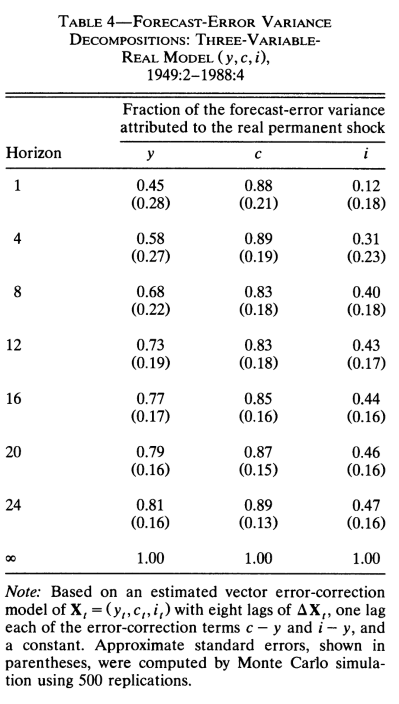

To calculate the FEVD, we only need to know the companion matrix, $A$ and the structural part, $B_0^{-1}$

1). Estimate the FEVD and set up a table as above. Consider how we find the infinite horizon. Use the function "FEVD" from s_master. You should have everything from above.

You need to set the horizon h to the largest value you are interested in.

Each row in the resulting FEVD-matrix corresponds to horizon h.

In [64]:
h = 2000

FEVD_long_run = FEVD(A,B0inv,K,p,h)

FEVD_long_run = FEVD_long_run[[0, 3, 7, 11, 15, 19, 23, h - 1], :3]

FEVD_long_run

/Users/nikolaizwisler/Documents/Universitet/Macro SVAR modeller/Macro-VAR-undervisning/s_master_2.py:149: ComplexWarning: Casting complex values to real discards the imaginary part
  VC[i,:]=Theta2[i,:] / Theta_sum
/Users/nikolaizwisler/Documents/Universitet/Macro SVAR modeller/Macro-VAR-undervisning/s_master_2.py:166: ComplexWarning: Casting complex values to real discards the imaginary part
  VC1[i,:]=Thetah[i,:] / Thetah_sum


array([[0.4489, 0.8759, 0.1184],
       [0.5792, 0.8913, 0.3116],
       [0.6831, 0.8250, 0.4028],
       [0.7313, 0.8274, 0.4287],
       [0.7650, 0.8473, 0.4436],
       [0.7900, 0.8671, 0.4554],
       [0.8095, 0.8851, 0.4689],
       [0.9962, 0.9986, 0.9737]])

2). How come the FEVD converges to 1 when $h \rightarrow \infty$? What would it mean if it converged to zero? Think about the number of common trends in the model...

3). Instead of using a table, we can also plot the results. Consider the following shocks on GDP:

- GDP on GDP
- Consumption on GDP
- Investment on GDP

Plot them in a stacked area plot. You can use "plt.stackplot". If done correctly, the shocks should sum to one, regardless of h chosen.

In [65]:
h = 40

FEVD_long_run = FEVD(A,B0inv,K,p,h)

Now create a horizon-vector that contains 1, 2, 3,..., until 40. Use the "np.arange"-function.

Create a new "data"-matrix that is 3x40, where each row corresponds to the FEVD of each shock on GDP. Think about the indexing needed to do this.

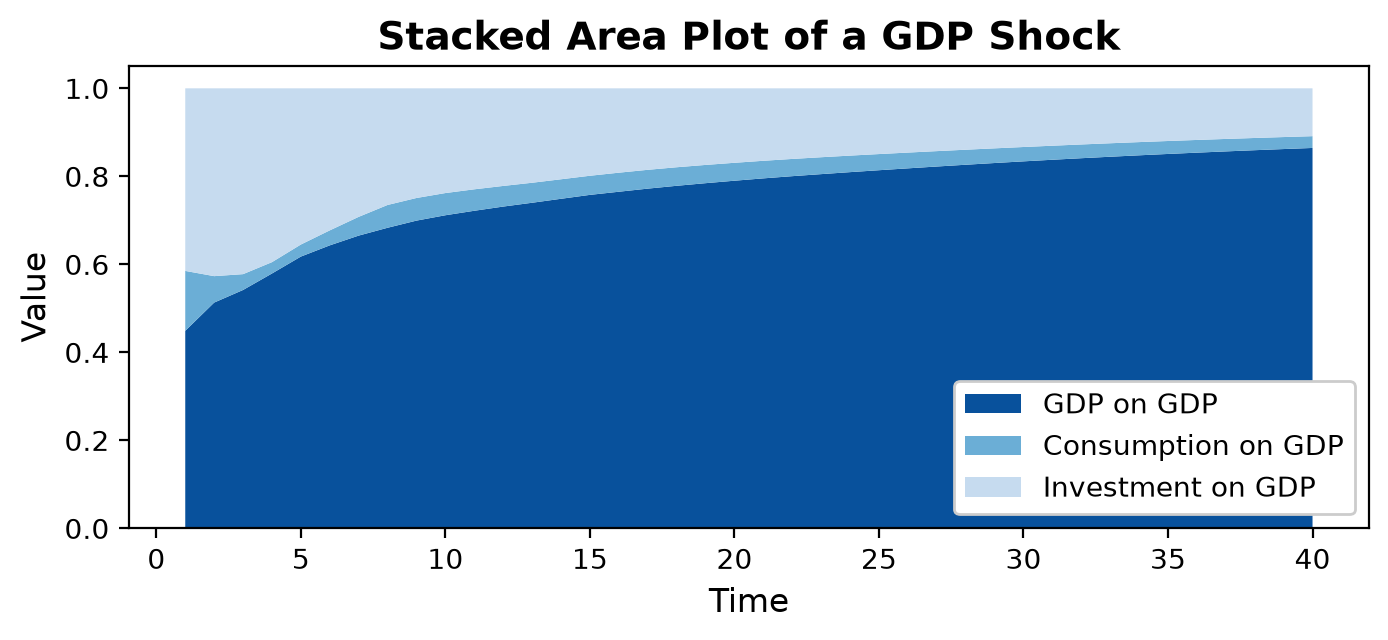

In [66]:
horizon = np.arange(1, h+1)

data = np.vstack([FEVD_long_run[:, 0], FEVD_long_run[:, 3], FEVD_long_run[:, 6]])
# Plot the stacked area chart
plt.figure(figsize=(8, 3))
plt.stackplot(horizon, data, labels=['GDP on GDP', 'Consumption on GDP', 'Investment on GDP'],
              colors=['#08519c', '#6baed6', '#c6dbef'])  # Different shades of blue
legend = plt.legend(loc='lower right', framealpha=1)  # Set framealpha to 1 to make the legend non-transparent
plt.xlabel("Time", fontsize=12)
plt.ylabel("Value", fontsize=12)
plt.title("Stacked Area Plot of a GDP Shock", fontsize=14, weight='bold')
plt.show()

#### HDecompotition

Now we change dataset, because the function "hdecomp" cannot include a trend and we would need a trend if we rewrite the above VECM to a VAR.

The data below is the same as exercise 6:

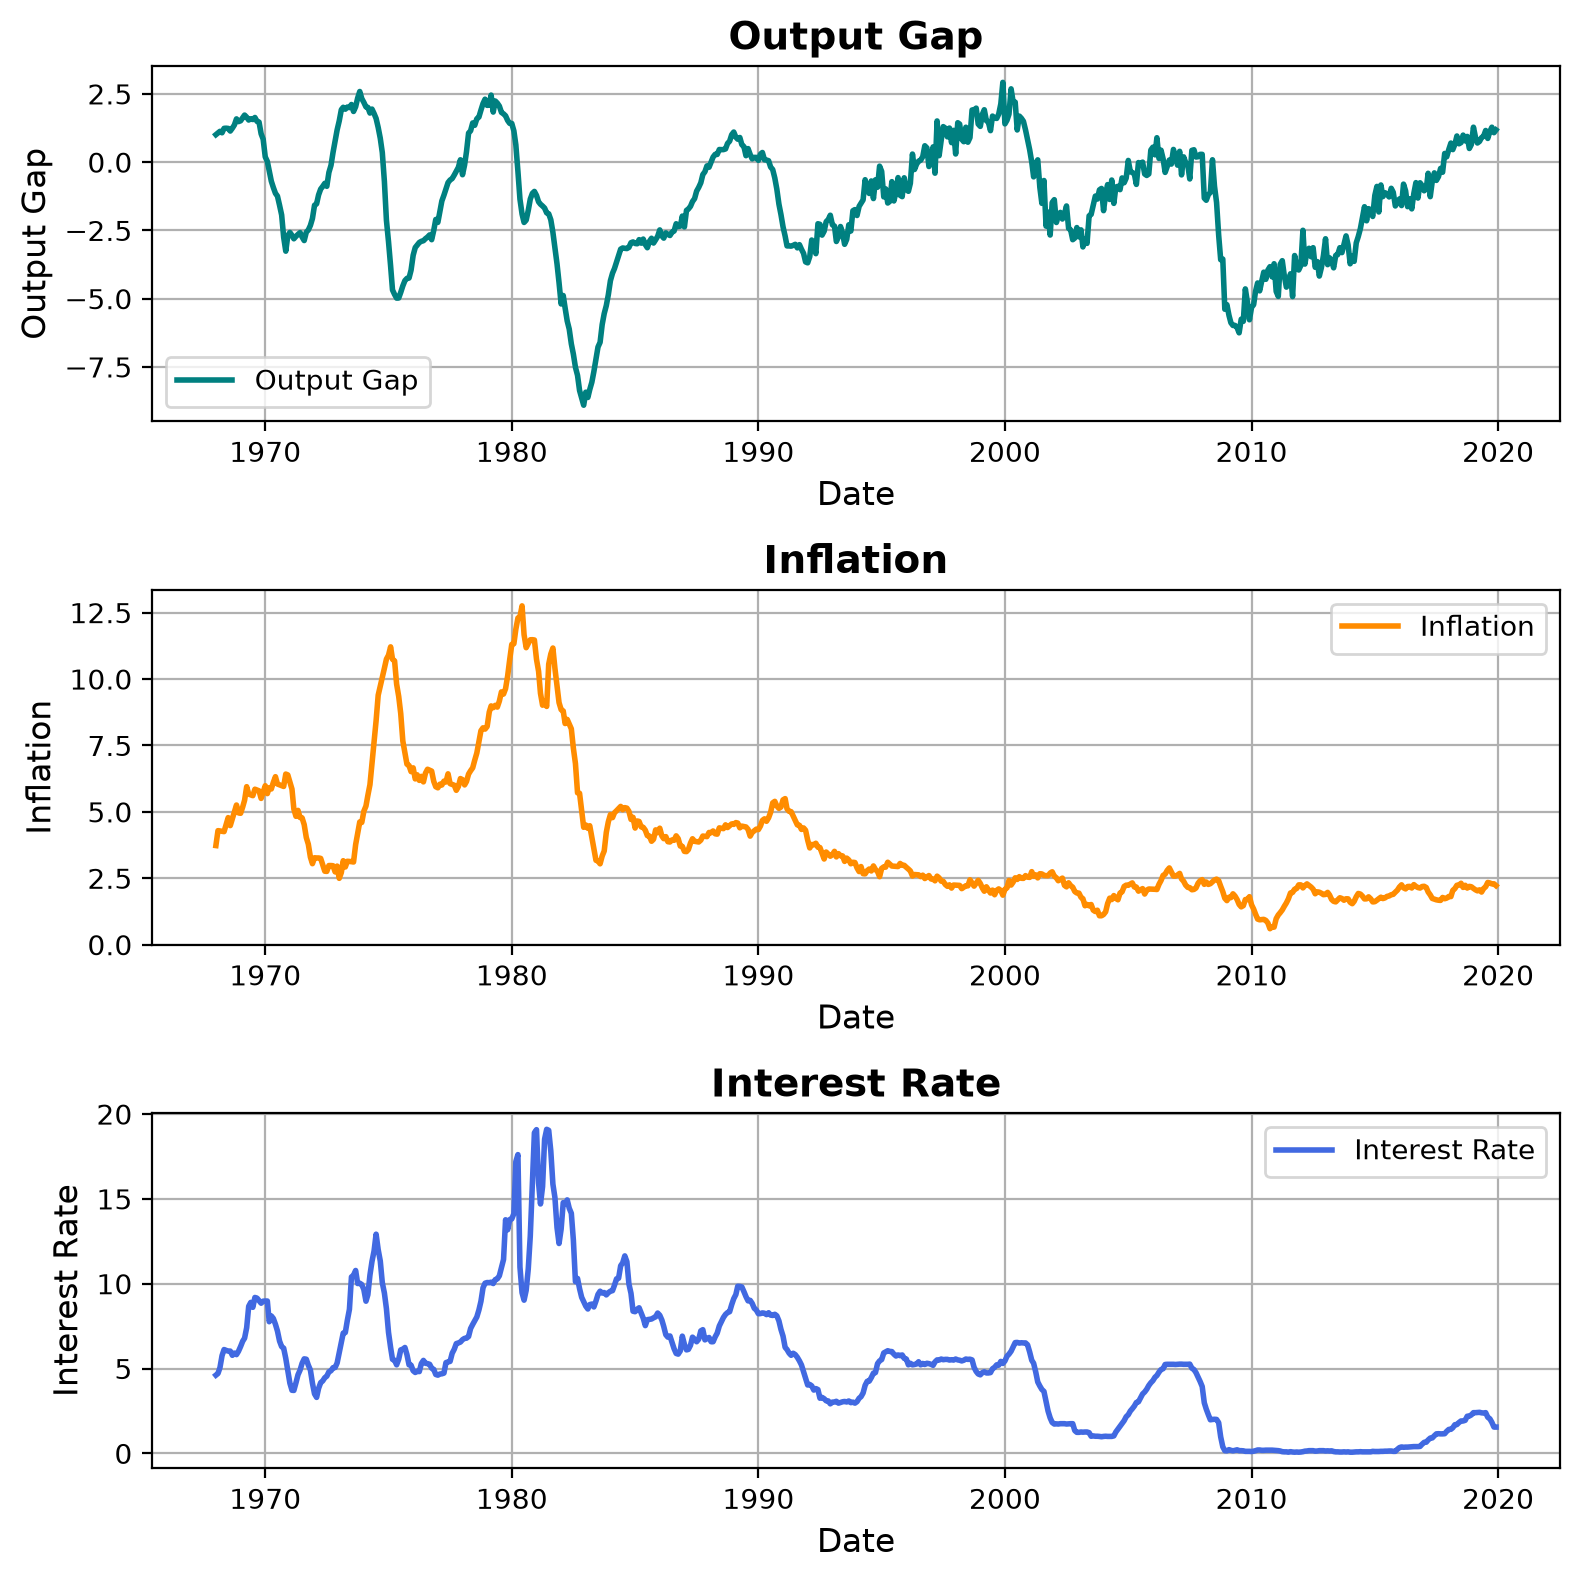

In [68]:
# Load the data
data = pd.read_excel('monetary_shock.xlsx')
dates = data['date']

y = np.array(data.iloc[:, 1:])


# Define the figure and subplots layout
fig, axs = plt.subplots(3, 1, figsize=(8, 8))

# Plot Output Gap
axs[0].plot(data['date'], data['Output Gap'], color='teal', linewidth=2, label='Output Gap')
axs[0].set_title('Output Gap', fontsize=14, weight='bold')
axs[0].set_xlabel('Date', fontsize=12)
axs[0].set_ylabel('Output Gap', fontsize=12)
axs[0].grid(True)
axs[0].legend()

# Plot Inflation
axs[1].plot(data['date'], data['Inflation'], color='darkorange', linewidth=2, label='Inflation')
axs[1].set_title('Inflation', fontsize=14, weight='bold')
axs[1].set_xlabel('Date', fontsize=12)
axs[1].set_ylabel('Inflation', fontsize=12)
axs[1].grid(True)
axs[1].legend()

# Plot Interest Rate
axs[2].plot(data['date'], data['Interest Rate'], color='royalblue', linewidth=2, label='Interest Rate')
axs[2].set_title('Interest Rate', fontsize=14, weight='bold')
axs[2].set_xlabel('Date', fontsize=12)
axs[2].set_ylabel('Interest Rate', fontsize=12)
axs[2].grid(True)
axs[2].legend()

# Adjust layout
plt.tight_layout()
plt.show()

Since $x_{t}$ can be written in it's VMA form, we could write it if we had an infinite time series:

\begin{equation*}
x_{t}=\sum_{s=0}^{t-1}\Theta_{s}v_{t-s}+\sum_{s=t}^{\infty}\Theta_{s}v_{t-s}
\end{equation*}

where $s=0$ is the start of our sample. Hence, $\sum_{s=t}^{\infty}\Theta_{s}v_{t-s}$ is unobserved. Therefore, we can only approximate:

\begin{equation*}
x_{t}\approx\sum_{s=0}^{t-1}\Theta_{s}v_{t-s}
\end{equation*}

or in other words, if we have a long enough time series, we can estimate $x_{t}$ as:

\begin{equation*}
\hat{x}_{t}=\sum_{s=0}^{t-1}\Theta_{s}v_{t-s}
\end{equation*}

Step 1 is to compute the structural MA coefficient matrices $\Theta_{0},\dots,\Theta_{T-1}$. Step 2 is to compute the structural shocks $v_{t}=B_{0}u_{t},t=1,\dots,T$. Step 3 is to match up each structural shock, say shock $j$, with the appropriate impulse response weight, as required by the structural moving average representation, to form $T\times1$ vectors of fitted values for variable $k$, denoted $\hat{y}_{k}^{(j)}$ for $j=1,\dots,K$.

If we have three variables, k=3, and we want to make a decomposition to variable 3, we can write:

\begin{equation*}
\hat{x}_{3t}^{(1)}=\sum_{i=0}^{t-1}\theta_{31,i}v_{1,t-i}
\end{equation*}

\begin{equation*}
\hat{x}_{3t}^{(2)}=\sum_{i=0}^{t-1}\theta_{32,i}v_{2,t-i},
\end{equation*}

\begin{equation*}
\hat{x}_{3t}^{(3)}=\sum_{i=0}^{t-1}\theta_{33,i}v_{3,t-i}.
\end{equation*}

First, we estimate $B_0^{-1}$ using the Cholesky decomposition:

In [69]:
t, K = y.shape

p = 12
con = 1
tr = 0
exog = 0

Beta, CovBeta, tratioBeta, residuals, X, SIGMA = VARlsExog(y, p, con, tr, exog)

def comp(Beta, p):
    K, Kp = Beta.T.shape
    A = np.vstack([Beta[0:K*p, 0:K].T, np.hstack([np.eye((p-1)*K), np.zeros(((p-1)*K, K))])])
    return A

A = comp(Beta, p)

B0inv = np.linalg.cholesky(SIGMA)

We need to find use:

    [HDinit,HDconst,HDshock,HDendo]=hdecomp(A,mu,What,B0inv,K,p,indep)

4). Find "mu" by taking out the constant from Beta. The constant lies in the back of Beta.


In [70]:
mu = Beta[-con, :].reshape(-1, 1)

5). Find "W_hat", which in our case is $v_t = B_0^{-1} \cdot u_t$.

In [71]:
What = np.linalg.inv(B0inv) @ residuals.T

6). Now we need "indep", which is lagged variables determined by $p$. Remember to remove the first $p$ rows, as they cannot be used for estimation. In other words, use the lagmatrix()-function.

In [73]:
indep = lagmatrix(y, p)

indep = indep[p:, :]

7). Estimate the historical decomposition, then plot the historical decomposition of GDP.

In [74]:
[HDinit,HDconst,HDshock,HDendo]=hdecomp(A,mu,What,B0inv,K,p,indep)

By theory, HDendo = HDinit + HDconst + sum(HDshock across all shocks). Therefore, check that y-HDendo is 0.

In [75]:
# HDendo lines up with y[p-1 : t-1], NOT y[p:]. hdecomp returns T-p rows that
# start one period before the first estimation observation, so the naive
# np.nansum(y - HDendo) fails on shapes and y[p:] is off by one.
hd = slice(p - 1, t - 1)

print("max |y - HDendo| :", np.nanmax(np.abs(y[hd] - HDendo)))
np.nansum(y[hd] - HDendo)

max |y - HDendo| : 4.796163466380676e-14


np.float64(-7.138151181251828e-12)

In [76]:
# The identity that actually matters:
#   HDendo = HDinit + HDconst + sum of HDshock over all shocks
print("max |HDendo - (HDinit + HDconst + sum HDshock)| :",
      np.nanmax(np.abs(HDendo - (HDinit + HDconst + HDshock.sum(axis=1)))))

max |HDendo - (HDinit + HDconst + sum HDshock)| : 0.0


HDshock(:,1,1) contains the effect of shock 1 on variable 1.

HDshock(:,2,1) contains the effect of shock 2 on variable 1 and so on.

Use this info to plot the HDshock for each shock on GDP.


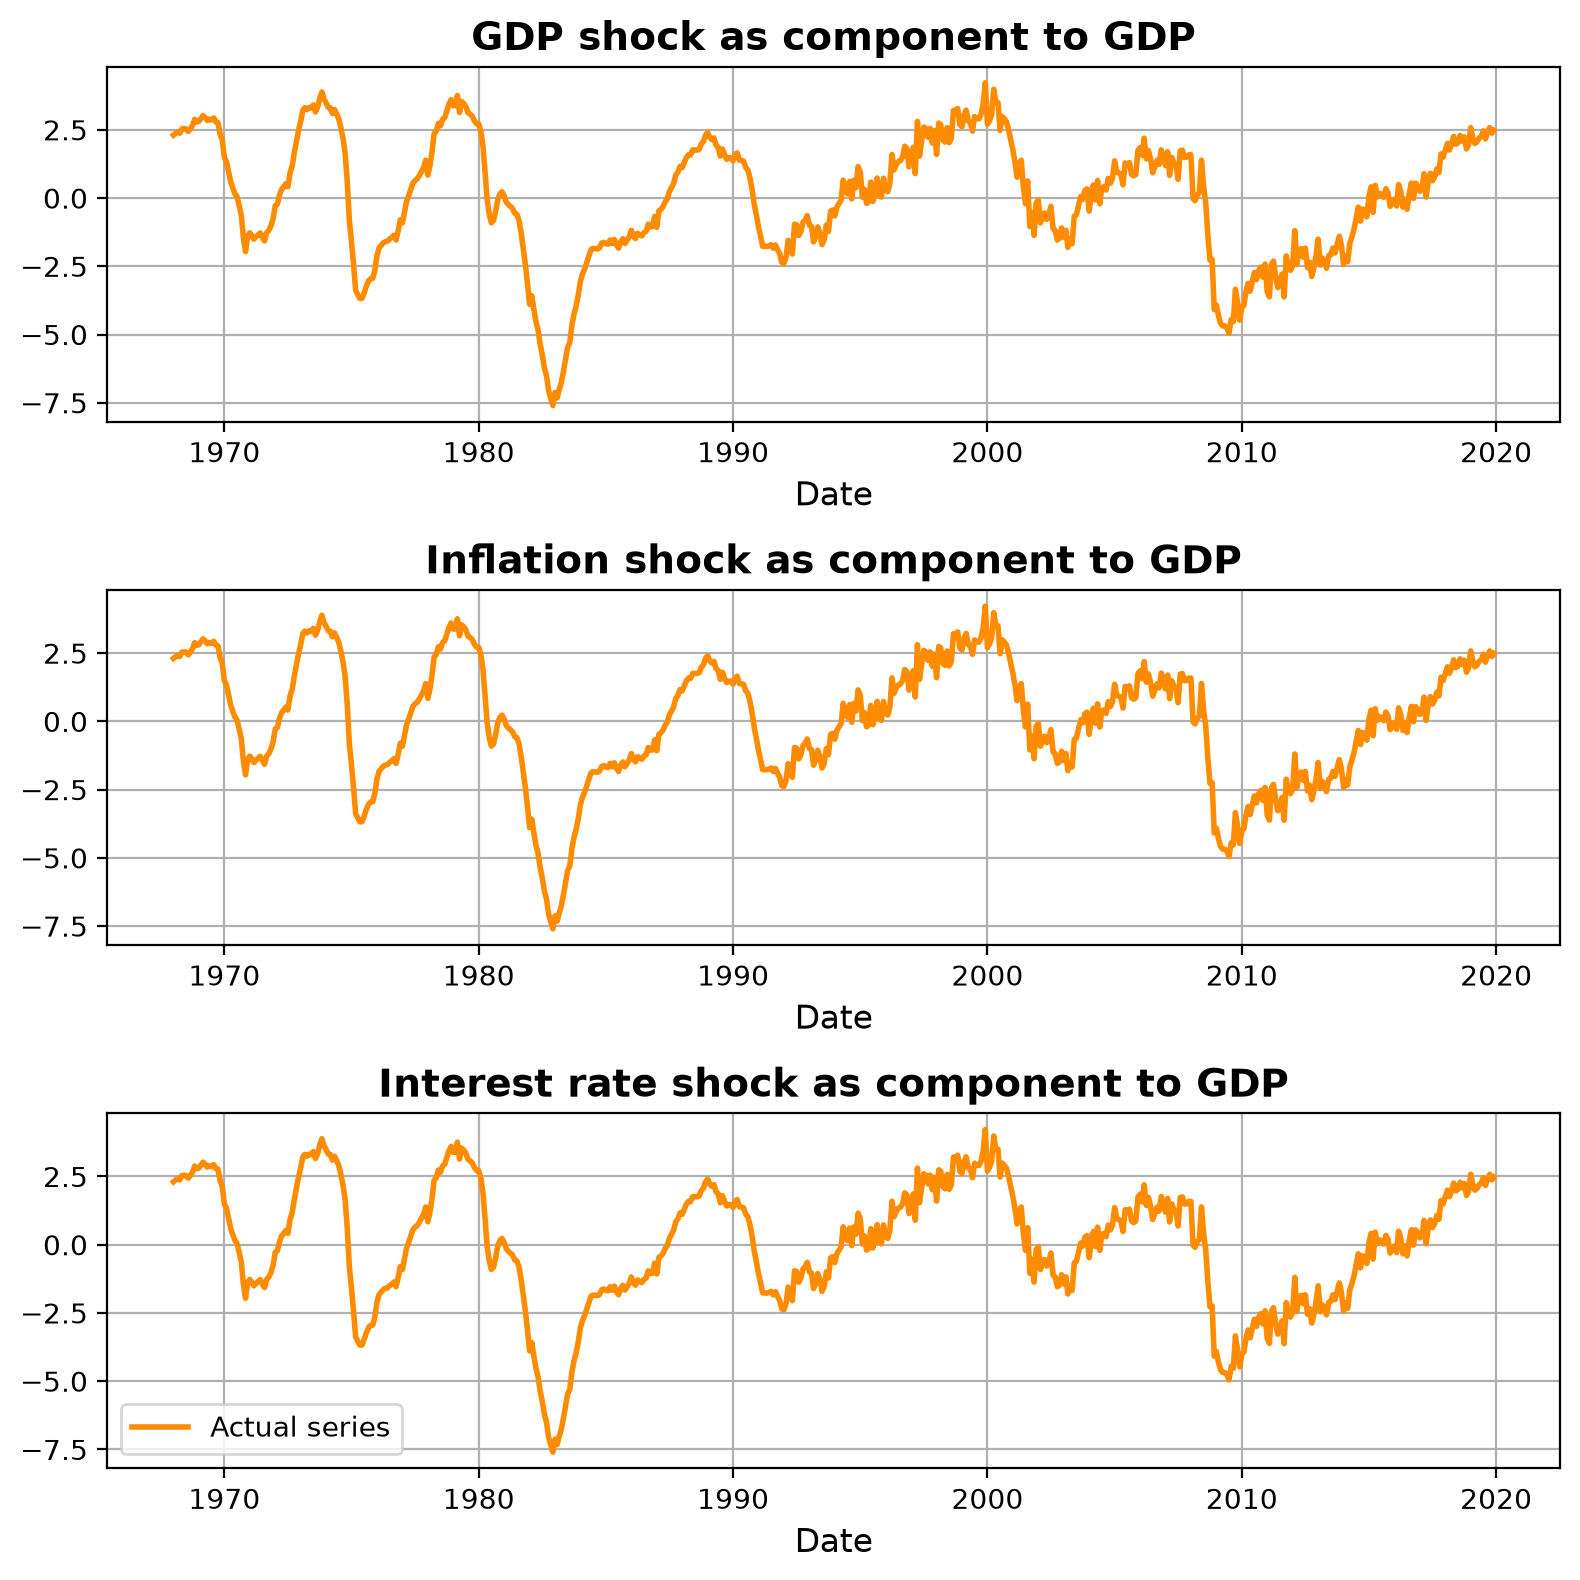

In [77]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8))


#so this is the contribution of shock 1 to variable 1.
#axes[0].plot(dates, HDshock[:, X, 0], color='teal', linewidth=2, label='Effect of shock')
axes[0].plot(dates, (y[:, 0] - np.mean(y[:, 0])), color='darkorange', linewidth=2, label='Actual series')
axes[0].set_title('GDP shock as component to GDP', fontsize=14, weight='bold')
axes[0].set_xlabel('Date', fontsize=12)
axes[0].grid(True)
#this is the contribution of shock 2 on variable 1.
#axes[1].plot(dates, HDshock[:, Y, 0], color='teal', linewidth=2, label='Effect of shock')
axes[1].plot(dates, (y[:, 0] - np.mean(y[:, 0])), color='darkorange', linewidth=2, label='Actual series')
axes[1].set_title('Inflation shock as component to GDP', fontsize=14, weight='bold')
axes[1].set_xlabel('Date', fontsize=12)
axes[1].grid(True)

#this is then interest rate shock (3rd shock) to variable 1: GDP
#axes[2].plot(dates, HDshock[:, Z, 0], color='teal', linewidth=2, label='Effect of shock')
axes[2].plot(dates, (y[:, 0] - np.mean(y[:, 0])), color='darkorange', linewidth=2, label='Actual series')
axes[2].set_title('Interest rate shock as component to GDP', fontsize=14, weight='bold')
axes[2].set_xlabel('Date', fontsize=12)
axes[2].grid(True)
axes[2].legend()

plt.tight_layout()
plt.show()


#### Generel tips for the homework

Question 1). Implement either of the two restrictions:

\begin{equation}
B_{0}^{-1}=\left[\begin{array}{ccccc}
\ast & 0 & 0 & 0 & 0\\
\ast & \ast & 0 & 0 & 0\\
\ast & \ast & \ast & 0 & 0\\
\ast & \ast & \ast & \ast & 0\\
\ast & \ast & \ast & \ast & \ast
\end{array}\right]\quad\text{or}\quad B_{0}^{-1}=\left[\begin{array}{ccccc}
\ast & 0 & 0 & 0 & 0\\
\ast & \ast & 0 & 0 & 0\\
\ast & \ast & \ast & 0 & 0\\
\ast & \ast & \ast & \ast & \ast\\
\ast & \ast & \ast & 0 & \ast
\end{array}\right]
\end{equation}

The two different restrictions will set the causal order differently. The first one implies that:

\begin{equation*}
\text{Foreign Interest Rate}\rightarrow\text{GDP}\rightarrow\text{Inflation}\rightarrow\text{Domestic Interest Rate}\rightarrow\text{Real Exchange Rate}
\end{equation*}

While the second implies that:

\begin{equation*}
\text{Foreign Interest Rate}\rightarrow\text{GDP}\rightarrow\text{Inflation}\rightarrow\text{Real Exchange Rate}\rightarrow\text{Domestic Interest Rate}
\end{equation*}

The following identification is not unique and does not a have single solution:

\begin{equation*}
B_{0}^{-1}=\left[\begin{array}{ccccc}
\ast & 0 & 0 & 0 & 0\\
\ast & \ast & 0 & 0 & 0\\
\ast & \ast & \ast & 0 & 0\\
\ast & \ast & \ast & \ast & \ast\\
\ast & \ast & \ast & \ast & \ast
\end{array}\right]
\end{equation*}

To implement this, we would need to impose long run restrictions too.

Question 2). The question states to estimate FEVD focusing on "the contribution of monetary policy shocks and real exchange rates shock". Make a table as KSPW where we have the shocks from inflation and the exchange rate to all other variables.

Question 3). We can relax our short-run restrictions and implement:

\begin{equation*}
B_{0}^{-1}=\left[\begin{array}{ccccc}
\ast & 0 & 0 & 0 & 0\\
\ast & \ast & 0 & 0 & 0\\
\ast & \ast & \ast & 0 & 0\\
\ast & \ast & \ast & \ast & \ast\\
\ast & \ast & \ast & \ast & \ast
\end{array}\right]
\end{equation*}

while also implementing:

\begin{equation*}
\Upsilon=\left[\begin{array}{ccccc}
\ast & \ast & \ast & \ast & \ast\\
\ast & \ast & \ast & \ast & \ast\\
\ast & \ast & \ast & \ast & \ast\\
\ast & \ast & \ast & \ast & \ast\\
\ast & \ast & \ast & 0 & \ast
\end{array}\right]
\end{equation*}

This implements the assumption that a monetary policy shock cannot affect the real exchange rate in the long run.

Question 4) Is about making the "vec2var"-function.

Question 5). Remember that all you need to estimate IRF and FEVD is "B0inv" and "A", where "A" is the companion matrix. Also remember that Björnland (2009) estimates the model as a VAR model and not a VECM model (reason why we need the vec2var-function)